# Chef Mystico — engine benchmark

This notebook measures the two halves of the food prediction engine against the 350-dish catalogue.

- **Forward mode** — you think of a dish, the engine asks yes/no questions and names it.
- **Reverse mode** — the engine hides a dish and reveals hints until you name it.

**The target.** In forward mode the engine's *first* guess must be right at least 95% of the time, for a player who answers every question and gets up to 10% of them wrong, within a hard cap of 40 questions.

**How it is measured.** A scripted player is handed a dish and answers every question from the catalogue, except that a set share of its answers are flipped to the wrong one or replaced by "not sure". Every dish is played several times against each kind of player. Because the scripted player knows the truth, a miss is the engine's fault and not the data's.

Everything here is reproducible: the simulations are seeded, and the same functions back `python -m tests.simulate`.

In [1]:
import sys, textwrap
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "app" / "services").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from app.config import settings
from app.services.catalog import get_catalogue
from app.services.tree import canonical_tree, forest
from ml import benchmark as bm

RUNS = 20      # times each dish is played against each player  ->  7,000 games per row
SEED = 7

pct = lambda v: f"{v:.1%}"
info = bm.describe_engine()
print(f"{info['dishes']} dishes · {info['questions']} questions {info['questions_by_kind']}")
print(f"bits needed to single out one dish: log2({info['dishes']}) = {info['bits_to_identify']:.2f}")
print(f"engine settings: guess at {info['guess_threshold']:.2f} confidence · cap {info['max_questions']} questions · "
      f"assumes {info['assumed_wrong_answer_rate']:.0%} of answers are wrong")

350 dishes · 183 questions {'attribute': 65, 'origin': 54, 'cuisine': 16, 'ingredient': 48}
bits needed to single out one dish: log2(350) = 8.45
engine settings: guess at 0.95 confidence · cap 40 questions · assumes 10% of answers are wrong


In [2]:
# Chart styling, used by every figure below.
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": SURFACE, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "lines.linewidth": 2, "lines.markersize": 7, "lines.solid_capstyle": "round",
    "legend.frameon": False,
})
RING = dict(markeredgecolor=SURFACE, markeredgewidth=2)   # a surface-coloured ring keeps markers legible


def draw_tree_top(node, depth=3):
    # The first `depth` levels of the fitted tree as a diagram.
    fig, ax = plt.subplots(figsize=(11.5, 4.6))
    ax.axis("off")

    def place(n, level, lo, hi):
        x, y = (lo + hi) / 2, -level
        label = n["dish"] if "dish" in n else textwrap.fill(n["question"], 22) + f"\n{n['dishes']} dishes"
        ax.text(x, y, label, ha="center", va="center", fontsize=9 - 0.7 * level, color=INK, zorder=3,
                bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=AXIS, lw=0.8))
        if "dish" in n or level == depth:
            return
        mid = (lo + hi) / 2
        for child, (c_lo, c_hi), tag in ((n["yes"], (lo, mid), "yes"), (n["no"], (mid, hi), "no")):
            cx = (c_lo + c_hi) / 2
            ax.plot([x, cx], [y, y - 1], color=AXIS, lw=1, zorder=1)
            ax.text((x + cx) / 2, y - 0.5, tag, ha="center", va="center", fontsize=8, color=INK2, zorder=2,
                    bbox=dict(fc=SURFACE, ec="none", pad=1.5))
            place(child, level + 1, c_lo, c_hi)

    place(node, 0, 0, 2 ** depth)
    ax.set_xlim(0, 2 ** depth)
    ax.set_ylim(-depth - 0.45, 0.45)
    return fig, ax

## 1. The question bank

Both modes read from one table: a row per question, a column per dish, each cell a yes or a no. The engine can only tell two dishes apart if some question gives them different answers, so the table is the ceiling on everything else.

The previous bank had 82 questions built from the dish flags and enum fields. It ignored the `country`, `cuisine` and `key_ingredients` columns. The new bank adds questions from those columns and from enum values that had no question of their own.

In [3]:
before, after = bm.bank_summary(legacy=True), bm.bank_summary()
rows = {
    "questions": "questions",
    "balanced_questions": "questions that split the catalogue between 20% and 80%",
    "collision_groups": "groups of dishes with identical answers",
    "dishes_indistinguishable": "dishes that cannot be told apart",
    "dishes_one_answer_from_another": "dishes one answer away from another dish",
    "dishes_two_answers_from_another": "dishes at most two answers away from another dish",
    "nearest_neighbour_median": "answers separating a dish from its nearest neighbour (median)",
}
display(pd.DataFrame({"previous bank": [before[k] for k in rows], "new bank": [after[k] for k in rows]},
                     index=list(rows.values())).astype(int))

print("Dishes the previous bank could not tell apart:")
for group in before["collisions"]:
    print("   ", " / ".join(group))

,previous bank,new bank
questions,82,183
questions that split the catalogue between 20% and 80%,18,19
groups of dishes with identical answers,8,0
dishes that cannot be told apart,20,0
dishes one answer away from another dish,65,2
dishes at most two answers away from another dish,111,26
answers separating a dish from its nearest neighbour (median),4,8


Dishes the previous bank could not tell apart:
    Orange Chicken / Sweet and Sour Chicken / Sesame Chicken
    Beef and Broccoli / Pepper Steak
    Mysore Pak / Gulab Jamun
    Naan / Garlic Naan / Tandoori Roti / Kulcha / Bhakri
    Aloo Gobi / Jeera Aloo
    Peda / Kalakand
    Mango Pickle / Mixed Pickle
    Saltimbocca alla Romana / Veal Scaloppine


The last three rows matter as much as the collisions. A dish that differs from its neighbour by a single answer is one mistaken answer away from being confused with it, and no amount of clever questioning can fix that. The new bank separates the typical dish from its nearest neighbour by twice as many answers.

## 2. The decision tree

A scikit-learn `DecisionTreeClassifier` is fitted on that table with the entropy criterion: one row per dish, one boolean feature per question, and the dish itself as the class label. At every node it picks the question that most evenly splits the dishes still in play. Since no two dishes share an answer pattern, the tree grows until each leaf holds exactly one dish.

In [4]:
tree = canonical_tree()
stats = tree.stats()
print(tree.classifier)
display(pd.Series({
    "leaves (one per dish)": stats["leaves"],
    "decision nodes": stats["nodes"] - stats["leaves"],
    "questions used, of those available": f"{stats['questions_used']} of {stats['questions_available']}",
    "questions to reach a dish, mean": round(stats["mean_depth"], 2),
    "questions to reach a dish, most": stats["max_depth"],
    "theoretical minimum, log2(dishes)": round(stats["ideal_depth"], 2),
    "dishes reached by honest answers": pct(stats["training_accuracy"]),
}, name="canonical tree").to_frame())

DecisionTreeClassifier(criterion='entropy', random_state=0)


,canonical tree
leaves (one per dish),350
decision nodes,349
"questions used, of those available",119 of 183
"questions to reach a dish, mean",8.56
"questions to reach a dish, most",10
"theoretical minimum, log2(dishes)",8.45
dishes reached by honest answers,100.0%


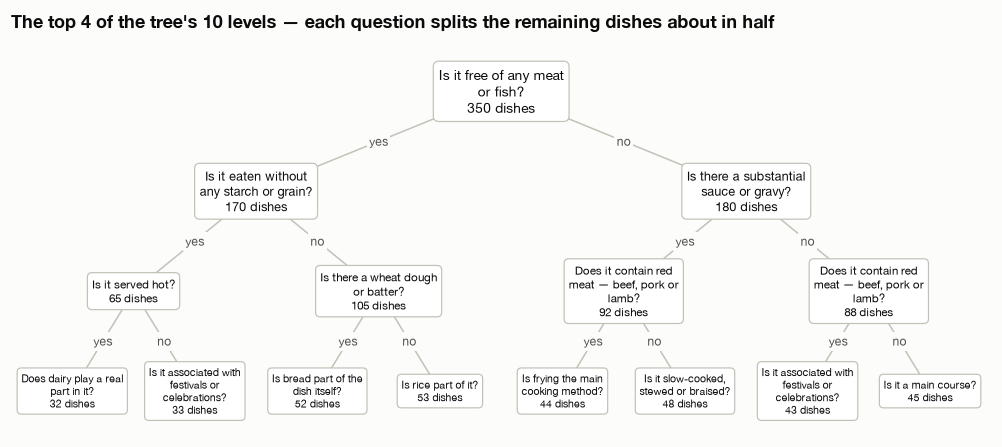

In [5]:
fig, ax = draw_tree_top(tree.to_dict(), depth=3)
ax.set_title(f"The top 4 of the tree's {stats['max_depth']} levels — each question splits the remaining dishes about in half", loc="left")
plt.show()

The average is within a fraction of a question of the theoretical minimum, so the splits are close to perfectly balanced. The full tree is exported by `python -m ml.decision_tree` and can be browsed at `/tree` while the server is running.

**Where a tree alone falls short.** A decision tree takes every answer at face value. One wrong answer sends it down the wrong branch and it can never come back:

In [6]:
hard = pd.DataFrame(bm.hard_tree_table(runs=RUNS, seed=SEED))
display(pd.DataFrame({
    "player": hard["player"],
    "reaches the right dish": hard["first_guess"].map(pct),
    "95% interval": [f"{pct(a)} – {pct(b)}" for a, b in zip(hard["first_guess_low"], hard["first_guess_high"])],
    "questions (mean)": hard["mean_questions"].round(1),
}).set_index("player"))

,reaches the right dish,95% interval,questions (mean)
player,,,
honest,100.0%,99.9% – 100.0%,8.6
5% wrong,65.2%,64.1% – 66.3%,8.5
10% wrong,42.2%,41.0% – 43.3%,8.5
20% not sure,40.9%,39.7% – 42.0%,8.5
10% wrong + 10% not sure,28.6%,27.5% – 29.6%,8.5
15% wrong,25.6%,24.6% – 26.7%,8.5
15% wrong + 15% not sure,14.6%,13.8% – 15.5%,8.5


Perfect for an honest player, and useless once a tenth of the answers are wrong. That is why the tree is not what plays forward mode. It is used where every answer is known to be true: in reverse mode, where the engine itself supplies the answers (section 4).

## 3. Forward mode: the Bayesian engine

The engine that reads your mind keeps the tree's split rule and drops its hard splits.

- **Belief, not a shortlist.** It holds a probability for every dish. An answer multiplies each dish's probability by how likely that answer is for that dish, then renormalises (Bayes' rule). A dish that disagrees with an answer is demoted, never deleted, so it can recover.
- **An answer model.** It assumes a player's answer matches the catalogue 90% of the time. Ingredient and regional-cuisine questions are trusted a little less, because the catalogue lists only each dish's defining ingredients and cuisine labels blur at the edges.
- **Question choice.** At every step it asks the question with the highest expected information gain over the current belief: the same criterion the tree uses, recomputed for the situation at hand.
- **Stopping rule.** It names a dish only once that dish holds 95% of the probability, or when it runs out of useful questions or reaches the cap. If the answer model matches the player, a guess made at 95% confidence is right 95% of the time. That is what the accuracy target rests on.

The table plays every dish twenty times against each scripted player. The first three rows are the target; the rest are stress cases, shown so the limits are visible. *First guess right* is the target metric. *Right within 3 guesses* is how often the engine gets there before conceding. *Floor* is the Shannon bound: the average number of questions any engine would need for that player, because a noisy answer carries less than one bit.

In [7]:
forward = pd.DataFrame(bm.forward_table(runs=RUNS, seed=SEED))

def show_forward(table):
    return pd.DataFrame({
        "player": table["player"],
        "first guess right": table["first_guess"].map(pct),
        "95% interval": [f"{pct(a)} – {pct(b)}" for a, b in zip(table["first_guess_low"], table["first_guess_high"])],
        "right within 3 guesses": table["within_guesses"].map(pct),
        "questions (mean)": table["mean_questions"].round(1),
        "questions (90th pct)": table["p90_questions"].astype(int),
        "questions (most)": table["max_questions"],
        "floor": table["shannon_floor"].round(1),
        "counts toward the target": np.where(table["in_target"], "yes", "stress case"),
    }).set_index("player")

display(show_forward(forward))

target = forward[forward["in_target"]]
worst = target.loc[target["first_guess"].idxmin()]
print(f"Games per row: {int(forward['games'].iloc[0]):,}")
print(f"Target: first guess right >= 95% for players with up to 10% wrong answers, within {settings.max_questions} questions.")
print(f"Lowest of the target rows: {worst['player']} at {pct(worst['first_guess'])} "
      f"(95% interval {pct(worst['first_guess_low'])} – {pct(worst['first_guess_high'])}), "
      f"never more than {int(target['max_questions'].max())} questions.")
print("Target", "MET" if worst["first_guess_low"] >= 0.95 else
      ("met on the point estimate, but the interval reaches below 95%" if worst["first_guess"] >= 0.95 else "NOT MET"))

,first guess right,95% interval,right within 3 guesses,questions (mean),questions (90th pct),questions (most),floor,counts toward the target
player,,,,,,,,
honest,100.0%,99.9% – 100.0%,100.0%,11.4,12,19,8.5,yes
5% wrong,99.2%,98.9% – 99.4%,100.0%,13.9,19,40,11.8,yes
10% wrong,95.9%,95.4% – 96.3%,99.6%,17.4,26,40,15.9,yes
20% not sure,99.8%,99.6% – 99.9%,100.0%,14.6,18,34,10.6,stress case
10% wrong + 10% not sure,95.4%,94.9% – 95.9%,99.4%,19.4,30,40,17.7,stress case
15% wrong,86.5%,85.7% – 87.3%,96.4%,22.0,38,40,21.7,stress case
15% wrong + 15% not sure,81.8%,80.9% – 82.7%,93.1%,25.8,40,40,25.5,stress case


Games per row: 7,000
Target: first guess right >= 95% for players with up to 10% wrong answers, within 40 questions.
Lowest of the target rows: 10% wrong at 95.9% (95% interval 95.4% – 96.3%), never more than 40 questions.
Target MET


**Reading the table.**

- The target holds, and at 10% wrong answers the engine stays within about a question and a half of the floor. It could not ask many fewer questions and stay correct.
- An honest player pays for the robustness: about 11 questions, where the hard tree needs under 9. The engine cannot know in advance that this player never slips, so it double-checks.
- "Not sure" answers alone do little harm. Stacked on top of 10% wrong answers they cost about a point, which leaves that row at the 95% line rather than clear of it: every "not sure" spends a question without learning anything, and the engine sometimes runs out of questions that separate two similar dishes.
- At 15% wrong the engine trusts the player more than it should and commits too early. Section 5 says what to do about that.

### Before and after

The previous engine used the 82-question bank, guessed as soon as one dish reached 55% (or 32% after twelve questions), and stopped at 20 questions. It is replayed here through the same game loop. Measured as it actually shipped, before any change, it scored 96.7%, 77.3% and 54.2% first-guess accuracy for the honest, 5%-wrong and 10%-wrong players.

In [8]:
legacy = pd.DataFrame(bm.forward_table(runs=RUNS, seed=SEED, legacy=True))
display(pd.DataFrame({
    "player": forward["player"],
    "hard tree": hard["first_guess"].map(pct),
    "previous engine": legacy["first_guess"].map(pct),
    "Bayesian engine": forward["first_guess"].map(pct),
    "questions: previous": legacy["mean_questions"].round(1),
    "questions: Bayesian": forward["mean_questions"].round(1),
}).set_index("player").rename_axis("first guess right, by player"))

,hard tree,previous engine,Bayesian engine,questions: previous,questions: Bayesian
"first guess right, by player",,,,,
honest,100.0%,96.4%,100.0%,9.7,11.4
5% wrong,65.2%,77.1%,99.2%,11.2,13.9
10% wrong,42.2%,56.7%,95.9%,12.7,17.4
20% not sure,40.9%,89.7%,99.8%,11.8,14.6
10% wrong + 10% not sure,28.6%,55.0%,95.4%,13.8,19.4
15% wrong,25.6%,38.0%,86.5%,14.2,22.0
15% wrong + 15% not sure,14.6%,34.5%,81.8%,15.7,25.8


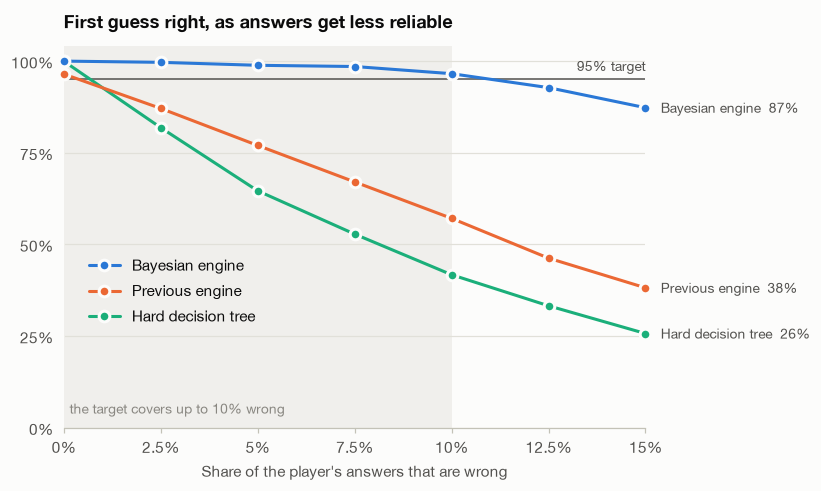

In [9]:
rates = [0.0, 0.025, 0.05, 0.075, 0.10, 0.125, 0.15]
sweep_players = [bm.Player(f"{r:.1%}", wrong=r) for r in rates]
curves = {
    "Bayesian engine": [r["first_guess"] for r in bm.forward_table(sweep_players, runs=6, seed=SEED)],
    "Previous engine": [r["first_guess"] for r in bm.forward_table(sweep_players, runs=6, seed=SEED, legacy=True)],
    "Hard decision tree": [r["first_guess"] for r in bm.hard_tree_table(sweep_players, runs=6, seed=SEED)],
}
x = [100 * r for r in rates]

fig, ax = plt.subplots(figsize=(8.6, 4.5))
fig.subplots_adjust(right=0.74)
ax.axvspan(0, 10, color="#f0efec", lw=0, zorder=0)
ax.text(0.15, 3, "the target covers up to 10% wrong", color=MUTED, fontsize=9, va="bottom")
ax.axhline(95, color=INK2, lw=1, zorder=1)
ax.text(15, 96.5, "95% target", color=INK2, fontsize=9, ha="right", va="bottom")
for (label, values), colour, layer in zip(curves.items(), (BLUE, ORANGE, AQUA), (5, 4, 3)):
    y = [100 * v for v in values]
    ax.plot(x, y, color=colour, marker="o", label=label, zorder=layer, clip_on=False, **RING)
    ax.annotate(f"{label}  {y[-1]:.0f}%", (x[-1], y[-1]), xytext=(10, 0), textcoords="offset points",
                va="center", color=INK2, fontsize=9, annotation_clip=False)
ax.set_xlim(0, 15)
ax.set_ylim(0, 104)
ax.set_xticks(x, [f"{v:g}%" for v in x])
ax.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("Share of the player's answers that are wrong")
ax.set_title("First guess right, as answers get less reliable")
ax.legend(loc="center left", bbox_to_anchor=(0.02, 0.36))
plt.show()

### Why the engine waits for 95%

The confidence it waits for is the dial between accuracy and length. Each row below is the same engine, for the 10%-wrong player, with a different threshold.

,first guess right,95% interval,questions (mean)
guess once a dish reaches,,,
0.55,70.2%,68.2% – 72.1%,13.8
0.70,83.8%,82.1% – 85.3%,14.8
0.80,89.1%,87.7% – 90.4%,15.5
0.90,93.4%,92.3% – 94.4%,16.3
0.95,96.6%,95.7% – 97.3%,17.3
0.98,97.0%,96.2% – 97.6%,18.2


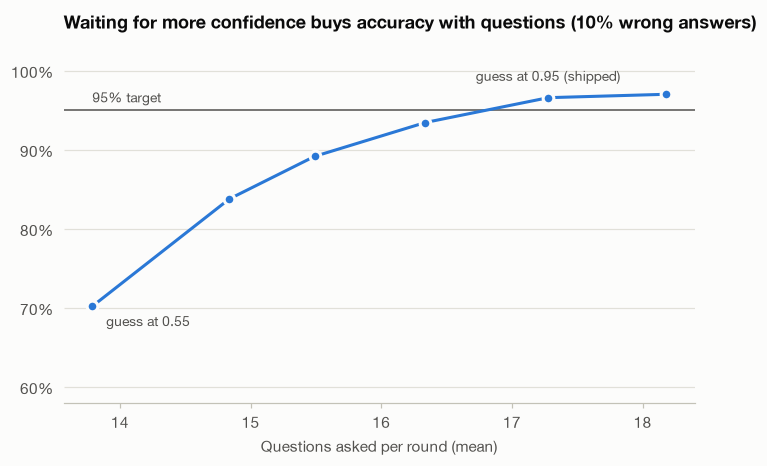

In [10]:
edge = next(p for p in bm.PLAYERS if p.label == "10% wrong")
sweep = pd.DataFrame(bm.threshold_sweep(edge, runs=6, seed=SEED))
display(pd.DataFrame({
    "guess once a dish reaches": sweep["threshold"].map("{:.2f}".format),
    "first guess right": sweep["first_guess"].map(pct),
    "95% interval": [f"{pct(a)} – {pct(b)}" for a, b in zip(sweep["first_guess_low"], sweep["first_guess_high"])],
    "questions (mean)": sweep["mean_questions"].round(1),
}).set_index("guess once a dish reaches"))

fig, ax = plt.subplots(figsize=(7.4, 4.2))
qs, acc = sweep["mean_questions"], 100 * sweep["first_guess"]
ax.axhline(95, color=INK2, lw=1, zorder=1)
ax.text(qs.min(), 95.6, "95% target", color=INK2, fontsize=9, ha="left", va="bottom")
ax.plot(qs, acc, color=BLUE, marker="o", zorder=3, **RING)
shipped = sweep["threshold"].sub(settings.guess_threshold).abs().idxmin()
first = sweep.index[0]
ax.annotate(f"guess at {sweep['threshold'][first]:.2f}", (qs[first], acc[first]), xytext=(9, -13),
            textcoords="offset points", color=INK2, fontsize=9)
ax.annotate(f"guess at {sweep['threshold'][shipped]:.2f} (shipped)", (qs[shipped], acc[shipped]), xytext=(0, 11),
            textcoords="offset points", color=INK2, fontsize=9, ha="center")
ax.set_xlabel("Questions asked per round (mean)")
ax.set_yticks(range(60, 101, 10), [f"{v}%" for v in range(60, 101, 10)])
ax.set_ylim(58, 103)
ax.set_title("Waiting for more confidence buys accuracy with questions (10% wrong answers)")
plt.show()

### Is the engine's confidence honest?

The stopping rule only works if "95% sure" means right 95% of the time. This groups the 10%-wrong player's rounds by the confidence the engine reported when it made its first guess, and compares that with how often the guess was right. Rounds below 0.95 are the ones that ended because the engine ran out of useful questions or hit the cap.

In [11]:
games = bm.run_forward(edge, runs=RUNS, seed=SEED)
calib = pd.DataFrame(bm.calibration(games))
display(pd.DataFrame({
    "confidence at first guess": calib["confidence"],
    "rounds": calib["games"],
    "share of rounds": (calib["games"] / calib["games"].sum()).map(pct),
    "engine said (mean)": calib["mean_stated"].map(pct),
    "actually right": calib["actually_right"].map(pct),
}).set_index("confidence at first guess"))

,rounds,share of rounds,engine said (mean),actually right
confidence at first guess,,,,
0.00–0.50,99,1.4%,39.6%,42.4%
0.50–0.80,192,2.7%,66.4%,69.8%
0.80–0.90,158,2.3%,85.6%,91.1%
0.90–0.95,208,3.0%,93.1%,96.6%
0.95–0.99,5869,83.8%,97.0%,97.4%
0.99–1.00,474,6.8%,99.2%,99.4%


The two columns on the right track each other, and where they differ the engine is the cautious one: it is not overconfident for a player its answer model fits.

The same rounds, split by why the engine made its first guess when it did:

In [12]:
reasons = pd.DataFrame(bm.stop_reasons(games))
display(pd.DataFrame({
    "first guess made because the engine": reasons["first guess made because the engine"],
    "share of rounds": reasons["share"].map(pct),
    "first guess right": reasons["first_guess"].map(pct),
    "confidence (mean)": reasons["mean_confidence"].map(pct),
    "questions (mean)": reasons["mean_questions"].round(1),
}).set_index("first guess made because the engine"))

,share of rounds,first guess right,confidence (mean),questions (mean)
first guess made because the engine,,,,
reached 0.95 confidence,90.6%,97.6%,97.2%,16.5
ran out of useful questions,8.1%,83.3%,77.9%,23.4
hit the 40-question cap,1.3%,53.4%,59.9%,40.0


Nearly all the misses come from rounds where the engine was forced to guess before it was sure. Those are dishes with a close neighbour in the catalogue: once the few questions that separate the pair have been spent, nothing else can tell them apart. More attributes on the dishes, not a different algorithm, is what would shrink that group.

## 4. Reverse mode: the hint ladder

When the engine hides a dish, the hints are that dish's own root-to-leaf path through a fitted tree, read out as statements. Forward mode asks those questions; here the engine answers them itself, so every answer is true and the tree's weakness from section 2 does not apply.

Each tree node is the most even split of the dishes still in play, so each hint removes about half of them. The dish's four hand-written clues are woven around that ladder: the first opens the round, the second arrives once only a handful of dishes still fit, and the last two close it.

The profile below builds the plan for every dish on each of the six trees the game draws from, and counts how many dishes still fit after each generated hint.

In [13]:
profile = bm.ladder_profile()
ladder = pd.DataFrame(profile["rows"])
display(pd.DataFrame({
    "generated hint": ladder["trait"],
    "dishes still fitting (median)": ladder["median_left"].astype(int),
    "dishes still fitting (worst round)": ladder["worst_left"],
    "rounds where only one dish fits": ladder["already_unique"].map(pct),
    "rounds reaching this hint": ladder["rounds_reaching_it"],
}).set_index("generated hint"))

print(f"Rounds profiled: {profile['plans']:,} ({len(get_catalogue().dishes)} dishes x {len(forest())} trees)")
print(f"Hints per round, both kinds: mean {profile['mean_hints']:.1f}, from {profile['min_hints']} to {profile['max_hints']}")
print(f"Earliest generated hint that leaves a single dish: number {profile['earliest_unique_trait']}")
print(f"Generated hints that contain part of the dish's own name: {profile['name_leaks']}")
print(f"Rounds where the generated hints alone do not single the dish out: {profile['ladders_needing_written_clues']} "
      f"({profile['ladders_needing_written_clues'] / profile['plans']:.1%}) — the written clues finish those")

,dishes still fitting (median),dishes still fitting (worst round),rounds where only one dish fits,rounds reaching this hint
generated hint,,,,
1,180,209,0.0%,2100
2,94,119,0.0%,2100
3,45,75,0.0%,2100
4,23,46,0.0%,2100
5,12,27,0.0%,2100
6,6,15,0.0%,2100
7,3,10,3.7%,2098
8,2,9,40.7%,1993
9,1,3,86.3%,1157


Rounds profiled: 2,100 (350 dishes x 6 trees)
Hints per round, both kinds: mean 12.6, from 10 to 15
Earliest generated hint that leaves a single dish: number 6
Generated hints that contain part of the dish's own name: 0
Rounds where the generated hints alone do not single the dish out: 58 (2.8%) — the written clues finish those


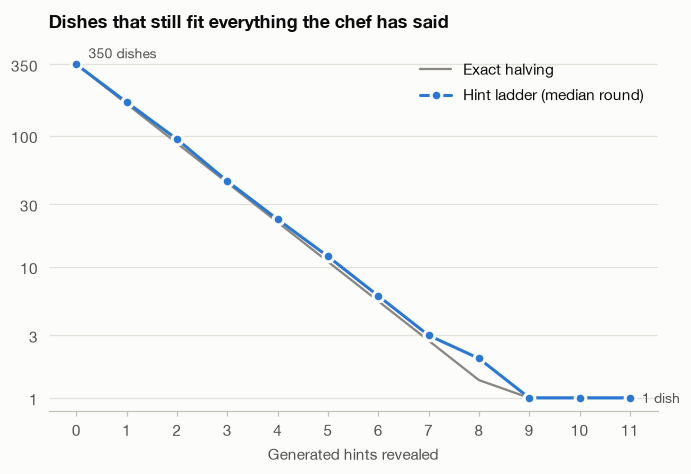

In [14]:
steps = [0] + ladder["trait"].tolist()
median = [len(get_catalogue().dishes)] + ladder["median_left"].tolist()
halving = [len(get_catalogue().dishes) / 2 ** k for k in steps]

fig, ax = plt.subplots(figsize=(8.2, 4.3))
fig.subplots_adjust(right=0.8)
ax.plot(steps, [max(v, 1) for v in halving], color=MUTED, lw=1.5, label="Exact halving", zorder=2)
ax.plot(steps, median, color=BLUE, marker="o", label="Hint ladder (median round)", zorder=3, clip_on=False, **RING)
ax.set_yscale("log")
ax.set_yticks([1, 3, 10, 30, 100, 350], ["1", "3", "10", "30", "100", "350"])
ax.minorticks_off()
ax.set_ylim(0.8, 480)
ax.set_xticks(steps)
ax.set_xlabel("Generated hints revealed")
ax.set_title("Dishes that still fit everything the chef has said")
ax.annotate("350 dishes", (0, 350), xytext=(8, 4), textcoords="offset points", color=INK2, fontsize=9)
ax.annotate("1 dish", (steps[-1], 1), xytext=(8, 0), textcoords="offset points", color=INK2, fontsize=9,
            va="center", annotation_clip=False)
ax.legend(loc="upper right")
plt.show()

The ladder tracks exact halving, which is the smoothest a sequence of yes/no facts can be: no hint is wasted and none gives the game away early. The summary above gives the earliest hint at which any round is down to a single dish.

One round, as the player would see it. A hint marked *clue* is hand-written; a *trait* comes from the tree.

In [15]:
from app.services import hints

catalogue = get_catalogue()
dish = catalogue.get("Mole Poblano")
plan = hints.build_plan(dish, catalogue.names, tree_index=0)
state = {"plan": plan, "revealed": [], "contrast": None}
rows = []
for i, step in enumerate(plan):
    state["revealed"].append(i)
    rows.append({"hint": i + 1, "kind": step["kind"],
                 "dishes still fitting": hints.candidates_left(state, catalogue.names),
                 "what the chef says": step["text"]})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index("hint").style.set_properties(**{"text-align": "left"}))

,kind,dishes still fitting,what the chef says
hint,,,
1,clue,350,Legend blames a panicking convent cook who emptied her whole pantry into one pot for a visiting archbishop.
2,trait,180,It contains meat or fish.
3,trait,92,It comes with a substantial sauce or gravy.
4,trait,48,It contains no red meat.
5,trait,25,"It is slow-cooked, stewed or braised."
6,trait,13,It does not come from Asia.
7,trait,6,It is spicy.
8,trait,3,Nuts or seeds are a significant ingredient.
9,clue,3,"It is the pride of Puebla, served at weddings and christenings, and traditionally ground by hand on a volcanic stone slab."


A wrong guess changes the order. If the guessed dish contradicts a hint already given, the chef points back at that hint and reveals nothing new. Otherwise the next hint is the split where the guess and the hidden dish part ways in the tree, which is the one fact that rules the guess out.

## 5. What these numbers do not show

- **The scripted player's mistakes are independent coin flips. A real player's are not.** Someone who wrongly believes a dish is vegetarian will answer every related question the same wrong way, and the engine will count that one belief as several pieces of evidence. Expect live first-guess accuracy to be lower than the figures above until the answer model is fitted to real play.
- **The target is conditional.** It holds for a player who answers every question and is wrong up to 10% of the time. The stress rows in section 3 show what happens beyond that.
- **The answer-model numbers are assumptions.** 90% for ordinary questions, less for ingredients and regional cuisines. None of them has been fitted to data yet.
- **Only catalogue dishes can be found.** A player thinking of a dish outside the 350 will always beat the engine.

The server records every answer. Once real rounds have been played, `GET /api/analytics/answer-noise` reports how often players' answers actually matched the catalogue, by kind of question and for the noisiest individual questions. Those figures replace the assumed ones in `app/config.py`, and this notebook can then be re-run against the corrected model.